In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import splprep, splev

from mcap.reader import make_reader
from mcap_ros2.decoder import DecoderFactory

from numpy.typing import NDArray
from typing import Tuple, Optional, List

In [2]:
def get_distance(x: NDArray, y: NDArray) -> float:
    return np.sqrt(np.sum(np.square(x - y)))


def average_points(points: NDArray, num_points: int) -> NDArray:
    """Loop over a list of points and average `num_points` of them. Returns a list of averaged points."""

    max_index = int(len(points) / num_points)
    averaged_points = np.zeros((max_index, 3))

    for i in range(max_index):
        average = np.mean(points[i * num_points: (i + 1) * num_points], axis=0)
        averaged_points[i, :] = average

    return averaged_points


def extract_point(point, strip_z_component: bool) -> NDArray:
    """Transform a given point from a ros2 vector object to a NumPy array and return it."""

    vec = np.zeros(3)
    vec[0] = point.x
    vec[1] = point.y

    if not strip_z_component:
        vec[2] = point.z

    return vec

# Signed polygon area trick (negative means clockwise).
def is_clockwise(points: NDArray) -> bool:
    signed_area = 0.0

    for i in range(len(points)):
        current_point = points[i]
        next_point = points[(i + 1) % len(points)]

        signed_area += current_point[0] * next_point[1] - next_point[0] * current_point[1]

    return signed_area < 0

In [3]:
def remove_near_duplicates_and_overlays(points: NDArray) -> NDArray:
    """Removes consecutive near duplicates and cuts of the end of the array in case of overlap with the start.
    The function assumes previous averaging as else the condition detection is highly unreliable due to small
    positional errors of the points."""

    # Compute distances between consecutive original points.
    distances = np.array([get_distance(points[i + 1], points[i])for i in range(len(points) - 1)])

    # Now the average spread and some rather arbitrary bound
    avg_spread = np.mean(distances)
    minimum_spread = avg_spread / 1.5

    # Keep the first point, then accumulate distance until keeping another.
    keep_mask = np.zeros(len(points), dtype=bool)
    keep_mask[0] = True

    accumulated_distance = 0.0

    for i in range(1, len(points)):
        accumulated_distance += distances[i - 1]

        if accumulated_distance >= minimum_spread:
            keep_mask[i] = True
            accumulated_distance = 0.0

    points = points[keep_mask]

    # Inspect the end of the recording for start/end overlap.
    first_point = points[0]
    last_distance = get_distance(points[-1], first_point)

    if last_distance > avg_spread:
        closest_index = len(points) - 1
        closest_distance = last_distance
        previous_distance = last_distance
        consecutive_increases = 0

        # Exclude index 0: its distance to itself is always zero.
        for i in range(len(points) - 2, 0, -1):
            current_distance = get_distance(points[i], first_point)

            if current_distance < closest_distance:
                closest_distance = current_distance
                closest_index = i

            if current_distance > previous_distance:
                consecutive_increases += 1
            else:
                consecutive_increases = 0

            if consecutive_increases >= 2:
                points = points[:closest_index]
                break

            previous_distance = current_distance

    return points

In [4]:
# This can very likely be simplified (by a lot). But since it works, this is currently not a priority.
def identify_corners(points: NDArray, sample_spacing: float = 0.1,
                     window_distance: float = 0.20, minimum_corner_angle: float = 40.0) -> Tuple[NDArray, NDArray]:
    """Identify corner positions on a closed curve.

    Distances are in metres and the angle threshold is in degrees.
    Returns corner positions in curve order.
    """

    def estimate_heading(window_points: NDArray) -> float:
        middle_index = len(window_points) // 2

        first_average = np.mean(window_points[:middle_index], axis=0)
        second_average = np.mean(window_points[middle_index:], axis=0)

        direction = second_average - first_average

        return np.degrees(np.arctan2(direction[1], direction[0]))

    # Include the closing segment when computing distances.
    if np.array_equal(points[0], points[-1]):
        closed_points = points
    else:
        closed_points = np.vstack((points, points[0]))

    distances = np.linalg.norm(
        np.diff(closed_points[:, :2], axis=0),
        axis=1,
    )
    cumulative_distances = np.concatenate(([0.0], np.cumsum(distances)))
    total_distance = cumulative_distances[-1]

    # Resample at approximately equal physical distances.
    number_samples = int(np.ceil(total_distance / sample_spacing))

    sample_distances = np.linspace(
        0.0, total_distance, number_samples, endpoint=False
    )

    resampled_points = np.zeros((number_samples, points.shape[1]))

    for coordinate in range(points.shape[1]):
        resampled_points[:, coordinate] = np.interp(
            sample_distances,
            cumulative_distances,
            closed_points[:, coordinate],
        )

    actual_spacing = total_distance / number_samples
    window_size = int(round(window_distance / actual_spacing))

    # Repetition allows windows to wrap around either end of the curve.
    extended_points = np.vstack((
        resampled_points,
        resampled_points,
        resampled_points,
    ))

    turn_angles = np.zeros(number_samples)

    for i in range(number_samples):
        center_index = number_samples + i

        before_window = extended_points[
            center_index - window_size:center_index
        ]
        after_window = extended_points[
            center_index:center_index + window_size
        ]

        incoming_heading = estimate_heading(before_window)
        outgoing_heading = estimate_heading(after_window)

        angle_difference = abs(outgoing_heading - incoming_heading)

        if angle_difference > 180.0:
            angle_difference = 360.0 - angle_difference

        turn_angles[i] = angle_difference

    # Find strong local maxima.
    candidate_indices = []

    for i in range(number_samples):
        previous_angle = turn_angles[i - 1]
        next_angle = turn_angles[(i + 1) % number_samples]
        current_angle = turn_angles[i]

        if (
            current_angle > minimum_corner_angle
            and current_angle >= previous_angle
            and current_angle > next_angle
        ):
            candidate_indices.append(i)

    # Prefer the strongest candidate when several describe one corner.
    candidate_indices.sort(
        key=lambda index: turn_angles[index],
        reverse=True,
    )

    selected_indices = []

    for candidate_index in candidate_indices:
        too_close = False

        for selected_index in selected_indices:
            separation = abs(
                sample_distances[candidate_index]
                - sample_distances[selected_index]
            )
            separation = min(separation, total_distance - separation)

            if separation < window_distance:
                too_close = True
                break

        if not too_close:
            selected_indices.append(candidate_index)

    selected_indices = np.array(sorted(selected_indices), dtype=int)

    return resampled_points, selected_indices

In [5]:
def unit_normal_at_point(points: NDArray, point_index: int, clockwise: bool, is_outer: bool) -> NDArray:
    """Return the unit normal pointing toward the road."""

    # Only use two points for the points at the beginning and end of the array
    if point_index == 0:
        previous_point = points[0]
        next_point = points[1]

    elif point_index == len(points) - 1:
        previous_point = points[-2]
        next_point = points[-1]

        # Handle the 'normal' case
    else:
        previous_point = points[point_index - 1]
        next_point = points[point_index + 1]

    # Compute and normalize the tangent (while assuming there is no division by 0 per point construction)
    tangent = next_point[:2] - previous_point[:2]
    tangent_length = np.linalg.norm(tangent)
    tangent = tangent / tangent_length

    # Initially points left of the direction of traversal.
    inward_normal = np.array([-tangent[1], tangent[0]])

    if clockwise:
        inward_normal = -inward_normal

    if is_outer:
        return inward_normal

    return -inward_normal


def normal_line_intersection(point: NDArray, scaled_normal: NDArray, line_start: NDArray, line_end: NDArray) -> Optional[NDArray]:
    """Intersect a finite normal with one boundary edge. Returns a 2D point."""

    point = point[:2]
    normal = scaled_normal[:2]

    line_direction = line_end[:2] - line_start[:2]
    offset = line_start[:2] - point

    denominator = normal[0] * line_direction[1] - normal[1] * line_direction[0]

    # Parallel or collinear.
    parallel_bound = 1e-2
    if abs(denominator) < parallel_bound:  #1e-12:
        return None

    normal_fraction = (offset[0] * line_direction[1] - offset[1] * line_direction[0]) / denominator

    line_fraction = (offset[0] * normal[1] - offset[1] * normal[0]) / denominator

    if (0.0 < normal_fraction <= 1.0) and (0.0 <= line_fraction <= 1.0):
        return point + normal_fraction * normal

    return None

In [6]:
def fit_and_sample_spline(
        points: NDArray,
        number_samples: int = 100,
        rms_tolerance: float = 0.005,
        closed: bool = False,
    ) -> NDArray:
        """Fit a smoothing spline and return sampled 2D points."""

        points = np.asarray(points, dtype=float)[:, :2]

        if len(points) < 2:
            return points.copy()

        # Express the smoothing budget through an RMS fitting tolerance.
        smoothing_budget = len(points) * rms_tolerance**2
        spline_degree = min(3, len(points) - 1)

        spline, parameters = splprep(
            points.T,
            k=spline_degree,
            s=smoothing_budget,
            per=closed,
        )

        sample_parameters = np.linspace(0.0, 1.0, number_samples)
        sampled_x, sampled_y = splev(sample_parameters, spline)

        return np.column_stack((sampled_x, sampled_y))

In [7]:
class MapConstructor:
    def __init__(self, channel_topic: str = "tf"):
        # Initial data / overwritten after averaging
        self.outer: Optional[NDArray] = None
        self.inner: List[NDArray] = []

        # Track width (assumed essentially uniform everywhere)
        self.track_width: Optional[float] = None

        # Lists of point sequences describing distinct curve segments (separated by corners)
        self.outer_segments: List[NDArray]
        self.inner_segments: List[List[NDArray]] = []

        # Information for tangent direction of all closed curves
        self.outer_clockwise: bool
        self.inner_clockwise: List[bool]

        # Very nested representations of the intersection correspondences for each point from a given sequence
        # For one curve, we store: For each segment (if intersection found) -> current index (in segment we iterate
        # over), flag if outer (true = 1, false = 0), Other curve index, other segment index, the two indices of
        # that other segment that create the line that the scaled normal intersects. This creates a tuple:
        # (current_index, outer_flag, other_curve_index, other_segment_index, index_1, index_2)
        self.outer_curve_correspondences: List[NDArray] = []
        self.inner_curve_correspondences: List[NDArray] = []

        # Storing the 'cleaned up' / more efficient and compacted track segment pair data
        self.track_segment_maps = []

        # Store the track separation lines (as points)
        self.track_separation_lines = []

        # Store the fitted separation lines
        self.fitted_track_separation_lines = []

        # Testing variable (pre full loop)
        self.results: List[List] = []

        if channel_topic == "tf":
            self.channel_topic = "/tf"
        elif channel_topic == "odometry":
            self.channel_topic = "/mapping_tool/odometry"
        else:
            raise ValueError("channel_topic must be 'tf' or 'odometry'")

    def load_ros_bag(self, path: str, measurement_type: str, strip_z_component: bool = True) -> None:
        """Load a ros bag file, extract the data and store it. `measurement_type` is 'inner' or 'outer'.
        'inner' can be multiple measurements and will be appended. 'outer' can only be one and will be set or replaced."""

        with open(path, 'rb') as f:
            reader = make_reader(f, decoder_factories=[DecoderFactory()])

            points = []

            for i, (schema, channel, message, msg) in enumerate(
            reader.iter_decoded_messages(topics=[self.channel_topic])):
                if channel.topic == "/tf":
                    position = msg.transforms[-1].transform.translation
                else:
                    position = msg.pose.pose.position

                points.append(extract_point(position, strip_z_component))

        points = np.array(points)

        if measurement_type == "outer":
            self.outer = points
        elif measurement_type == "inner":
            self.inner.append(points)
        else:
            raise ValueError("measurement_type must be 'outer' or 'inner'")

        return None

    def build_averages(self, num_points: int) -> None:
        # Once for outer
        if self.outer is not None:
            self.outer = average_points(self.outer, num_points)

        # Then loop over inner
        for i, points in enumerate(self.inner):
            self.inner[i] = average_points(points, num_points)

        return None

    # Some of these functions should probably rather be split, such that they are modular and can do a specific and
    # more general task. Then we have an additional function that should then be called on a class instance to
    # compute the properties for all relevant elements. I.e., get_tangents() -> get_tangents_for_consecutive_segment().

    # Also, we still need to add the data validations and pre-processing functions. Validation should probably take
    # no parameter, while preprocessing should likely allow for a few 'customizations'.

    def preprocess(self) -> None:
        """Should be called after all curves have been added. Currently written out as one long function but should
         eventually probably be split into parts that can then be called here."""

        # 1. Remove consecutive (near) duplicates and handle the 'closed curve assumption' and apply start / end overlap correction.
        # First do it for outer, then for inner. The logic should stay the same though
        if self.outer is not None:
            self.outer = remove_near_duplicates_and_overlays(self.outer)

            # Compute orientations (before splitting into segments)
            self.outer_clockwise = is_clockwise(self.outer)

        for i in range(len(self.inner)):
            self.inner[i] = remove_near_duplicates_and_overlays(self.inner[i])

            # Compute orientations (before splitting into segments)
            self.inner_clockwise = [is_clockwise(curve) for curve in self.inner]

        return None

# """Loop over a line measurement and identify (actual) corner positions. For now maybe focus on 90 degrees
#         but should also work in general for all angles not too close to 180 degrees. Returns a list of points"""

    def split_points_into_consecutive_segments(self, points: NDArray) -> List[NDArray]:
        """Extract points that describe lines between identified corner points. Returns a list of point sequences."""

        # The general idea is that we want to loop over each curve that has corner points and then split these points into
        # segments — separated by corner points. For this, the first and last parts need to be combined to one segment (since
        # they are between two corners, if there are any)

        # Then, to ensure consistency, each segment should have (if there are) the corner points at the end. This ensures same
        # starting and end points which might be useful for later fitting. Also, the new corner points might be very close to existing
        # points. To have no issues with gradients, we will replace these close-to-corner-points by the corner points. And, this
        # is kind of a blessing in disguise, but if the points are very close, and we have our preprocessing function so we can use this to identify the corner points (via small distance)... However, I am unsure if this is always guaranteed to be the case.

        resampled_points, corner_indices = identify_corners(points)

        # With no corners, keep the complete curve as one closed segment.
        if len(corner_indices) == 0:
            return [np.vstack((resampled_points, resampled_points[0]))]

        segments = []

        for i in range(len(corner_indices)):
            start_index = corner_indices[i]
            end_index = corner_indices[(i + 1) % len(corner_indices)]

            if end_index > start_index:
                segment = resampled_points[start_index:end_index + 1].copy()
            else:
                # Wrap from the last corner through the recording start.
                segment = np.vstack((
                    resampled_points[start_index:],
                    resampled_points[:end_index + 1],
                ))

            segments.append(segment)

        return segments

    def split_curves_into_segments(self) -> None:
        """Here we just call split_points_into_consecutive_segments() for the outer and the inner curves."""
        if self.outer is not None:
            self.outer_segments = self.split_points_into_consecutive_segments(self.outer)

        for curve in self.inner:
            self.inner_segments.append(self.split_points_into_consecutive_segments(curve))

        pass

    def get_tangents_for_consecutive_segment(self, num_adjacent: int) -> NDArray:
        """Get the tangents at each point (estimated from 2n + 1 points, width n (num_adjacent) = 1 as default)."""
        pass

    def identify_consecutive_track_segments(self):
        """Loop over the consecutive segments and identify pairs of segments (or / and actually only sequences of these
        pairs) that bound consecutive track segments."""

        # Very nested representations of the intersection correspondences for each point from a given sequence
        # For one curve, we store: For each segment (if intersection found) -> current segment, current index (in
        # segment we iterate over), flag if outer (true = 1, false = 0), Other curve index, other segment index, the
        # two indices of that other segment that create the line that the scaled normal intersects. This creates a
        # tuple: (curve, current_segment, current_index, outer_flag, other_curve_index, other_segment_index, index_1, index_2)

        # First do it for the outer curve
        for s, segment in enumerate(self.outer_segments):
            for i in range(len(segment)):
                normal = unit_normal_at_point(
                    points=segment,
                    point_index=i,
                    clockwise=self.outer_clockwise,
                    is_outer=True,
                )

                # The 1.1 is a somewhat arbitrary factor to 'counter' map imperfections.
                scaled_normal = 1.1 * self.track_width * normal

                # Search the other segments of the outer boundary (Fix after big-map-trial)
                for k, other_segment in enumerate(self.outer_segments):
                    if k == s:
                        continue

                    for l in range(len(other_segment) - 1):
                        intersection = normal_line_intersection(
                            segment[i],
                            scaled_normal,
                            other_segment[l],
                            other_segment[l + 1],
                        )

                        if intersection is not None:
                            result = [s, i, 1, 0, k, l, l + 1]
                            self.outer_curve_correspondences.append(result)

                # Now we have to loop over the other segments (here only all other inner)
                for j, other_curve_segments in enumerate(self.inner_segments):
                    for k, other_segment in enumerate(other_curve_segments):
                        for l in range(len(other_segment) - 1):
                            intersection = normal_line_intersection(
                                segment[i],
                                scaled_normal,
                                other_segment[l],
                                other_segment[l + 1],
                            )

                            if intersection is not None:
                                # The intersection then lies between the points of other_segment at indices l and l + 1.
                                result = [s, i, 0, j, k, l, l + 1]

                                self.outer_curve_correspondences.append(result)

        # Now essentially the same thing (with one additional iteration for multiple inner curves)
        for c, curve_segments in enumerate(self.inner_segments):
            for s, segment in enumerate(curve_segments):
                for i in range(len(segment)):
                    normal = unit_normal_at_point(
                        points=segment,
                        point_index=i,
                        clockwise=self.inner_clockwise[c],
                        is_outer=False,
                    )

                    # The 1.1 allows for map imperfections.
                    scaled_normal = 1.1 * self.track_width * normal

                    closest_distance = float("inf")
                    best_result = None

                    # First search the outer segments.
                    for k, other_segment in enumerate(self.outer_segments):
                        for l in range(len(other_segment) - 1):
                            intersection = normal_line_intersection(
                                segment[i],
                                scaled_normal,
                                other_segment[l],
                                other_segment[l + 1],
                            )

                            if intersection is not None:
                                distance = np.linalg.norm(intersection - segment[i, :2])

                                if distance < closest_distance:
                                    closest_distance = distance
                                    best_result = [c, s, i, 1, 0, k, l, l + 1]

                    # Then search the remaining inner curves.
                    for j, other_curve_segments in enumerate(self.inner_segments):
                        if j == c:
                            continue

                        for k, other_segment in enumerate(other_curve_segments):
                            for l in range(len(other_segment) - 1):
                                intersection = normal_line_intersection(
                                    segment[i],
                                    scaled_normal,
                                    other_segment[l],
                                    other_segment[l + 1],
                                )

                                if intersection is not None:
                                    distance = np.linalg.norm(intersection - segment[i, :2])

                                    if distance < closest_distance:
                                        closest_distance = distance
                                        best_result = [c, s, i, 0, j, k, l, l + 1]

                    # Store at most one correspondence for this source point.
                    if best_result is not None:
                        self.inner_curve_correspondences.append(best_result)

    def clean_track_segment_maps(self) -> None:
        """Here we should clean up the (probably) highly redundant data of the identified consecutive track segments.
        We essentially want to go over the data and return a tuple:
        For outer: List of inner curves (Optional(List(List of segments (start index, stop index))) — or something
        like this. And then a similar structure for the outer curves..."""
        pass

    def clean_track_segment_maps(self) -> None:
        """Group point correspondences into matching boundary sections."""

        maximum_missed_points = 2

        # Put outer and inner results into the same representation:
        # (source, point_index, target, first_target_index, second_target_index)
        # Source and target are (outer_flag, curve_index, segment_index).
        correspondences = []

        # This might drastically be improved in terms of legibility using a dataclass...
        for result in self.outer_curve_correspondences:
            # For source: outer_flag, curve_index, segment_index
            # For target:
            source = (1, 0, result[0])
            target = tuple(result[2:5])

            correspondences.append((source, result[1], target, result[5], result[6]))

        for result in self.inner_curve_correspondences:
            source = (0, result[0], result[1])
            target = tuple(result[3:6])

            correspondences.append((source, result[2], target, result[6], result[7]))

        # Group by source segment, then follow its point order.
        correspondences.sort(key=lambda entry: (entry[0], entry[1]))

        current_source = None
        current_target = None

        start_index = 0
        previous_index = 0
        minimum_target_index = 0
        maximum_target_index = 0

        def save_current_run():
            self.track_segment_maps.append({
                "source": current_source,
                "target": current_target,
                "source_range": (start_index, previous_index + 1),
                "target_range": (minimum_target_index, maximum_target_index + 1)
            })

        for correspondence in correspondences:
            (
                source,
                point_index,
                target,
                first_target_index,
                second_target_index,
            ) = correspondence

            missed_points = point_index - previous_index - 1

            extend_current_run = (
                source == current_source
                and target == current_target
                and missed_points <= maximum_missed_points
            )

            if extend_current_run:
                minimum_target_index = min(minimum_target_index, first_target_index)
                maximum_target_index = max(maximum_target_index, second_target_index)

            else:
                if current_source is not None:
                    save_current_run()

                current_source = source
                current_target = target
                start_index = point_index

                minimum_target_index = first_target_index
                maximum_target_index = second_target_index

            previous_index = point_index

        if current_source is not None:
            save_current_run()

        # Collect the maps belonging to each source segment.
        maps_by_source = {}

        for segment_map in self.track_segment_maps:
            source = segment_map["source"]

            if source not in maps_by_source:
                maps_by_source[source] = []

            maps_by_source[source].append(segment_map)

        for source, source_maps in maps_by_source.items():
            if len(source_maps) < 2:
                continue

            outer_flag, curve_index, segment_index = source

            if outer_flag:
                points = self.outer_segments[segment_index]
            else:
                points = self.inner_segments[curve_index][segment_index]

            # Only join across the seam of an actually closed segment.
            if not np.array_equal(points[0], points[-1]):
                continue

            source_maps.sort(key=lambda entry: entry["source_range"][0])

            first_map = source_maps[0]
            last_map = source_maps[-1]

            if first_map["target"] != last_map["target"]:
                continue

            first_start, first_stop = first_map["source_range"]
            last_start, last_stop = last_map["source_range"]

            # Allow small unmatched gaps around the recording seam.
            missed_points = first_start + len(points) - last_stop

            if missed_points > maximum_missed_points:
                continue

            # Join the last run to the first using a wrapped source range.
            last_map["source_range"] = (last_start, first_stop)

            first_target_start, first_target_stop = first_map["target_range"]
            last_target_start, last_target_stop = last_map["target_range"]

            last_map["target_range"] = (
                min(first_target_start, last_target_start),
                max(first_target_stop, last_target_stop),
            )

            self.track_segment_maps.remove(first_map)

    def estimate_track_width(self, width: Optional[float] = None) -> None:
        """Get the width of the track (both directions, i.e. width between inner and outer). Assumes equal track width
        everywhere. If width is provided, this is used instead of running the algorithm to determine the width."""
        if width is not None:
            self.track_width = width
            return None

        # Handle algorithmic part here
        pass


    def get_segment_track_separation(self) -> None:
        self.track_separation_lines = []
        self.fitted_track_separation_lines = []

        kept_maps = []
        used_ranges = set()

        for segment_map in self.track_segment_maps:
            outer_flag, curve_index, segment_index = segment_map["source"]
            target_outer_flag, target_curve_index, target_segment_index = segment_map["target"]

            # Keep outer → inner, discard inner → outer.
            if not outer_flag and target_outer_flag:
                continue

            # Keep only one direction between inner curves.
            if not outer_flag and not target_outer_flag:
                if curve_index > target_curve_index:
                    continue

            # Keep only one direction between outer segments.
            if outer_flag and target_outer_flag:
                if segment_index > target_segment_index:
                    continue

            source_range_key = (
                tuple(segment_map["source"]),
                tuple(segment_map["source_range"]),
            )
            target_range_key = (
                tuple(segment_map["target"]),
                tuple(segment_map["target_range"]),
            )

            if (
                source_range_key in used_ranges
                or target_range_key in used_ranges
            ):
                continue

            if outer_flag:
                points = self.outer_segments[segment_index]
                clockwise = self.outer_clockwise
            else:
                points = self.inner_segments[curve_index][segment_index]
                clockwise = self.inner_clockwise[curve_index]

            start_index, stop_index = segment_map["source_range"]
            closed = np.array_equal(points[0], points[-1])

            if start_index > stop_index:
                point_indices = (
                    list(range(start_index, len(points) - 1))
                    + list(range(stop_index))
                )
            else:
                point_indices = range(start_index, stop_index)

            middle_points = []

            for point_index in point_indices:
                normal = unit_normal_at_point(
                    points=points,
                    point_index=point_index,
                    clockwise=clockwise,
                    is_outer=bool(outer_flag),
                )

                middle_point = (
                    points[point_index, :2]
                    + 0.5 * self.track_width * normal
                )

                middle_points.append(middle_point.tolist())

            kept_maps.append(segment_map)
            self.track_separation_lines.append(middle_points)

            used_ranges.add(source_range_key)
            used_ranges.add(target_range_key)

        self.track_segment_maps = kept_maps

    def merge_reverse_middle_points(self) -> None:
        merged_maps = []
        merged_middle_points = []
        mapping_indices = {}

        for segment_map, middle_points in zip(
            self.track_segment_maps,
            self.track_separation_lines,
        ):
            # Group by boundary-segment identities, ignoring index ranges.
            source = tuple(segment_map["source"])
            target = tuple(segment_map["target"])

            # Same key for A → B and B → A.
            mapping_key = tuple(sorted((source, target)))

            if mapping_key not in mapping_indices:
                mapping_indices[mapping_key] = len(merged_maps)
                merged_maps.append(segment_map)
                merged_middle_points.append([])

            index = mapping_indices[mapping_key]
            merged_middle_points[index].extend(middle_points)

        self.track_segment_maps = merged_maps
        self.track_separation_lines = merged_middle_points

    def fit_lines_with_splines(self) -> None:
        for middle_points in self.track_separation_lines:
            fitted_points = fit_and_sample_spline(np.array(middle_points))
            self.fitted_track_separation_lines.append(fitted_points)

    def get_crossing_bounds(self):
        """Get bounds of the segments that are not part of any track segment, i.e. spaces where there is more than one
        way to keep on driving."""
        pass

    # Some functions for plotting. For now though, rather just to see what's going on and to double-check.

    def plot_curves(self):
        if self.outer is not None:
            plt.scatter(self.outer[:,0], self.outer[:,1], s=1)

            resampled_points, corner_indices = identify_corners(self.outer)
            corner_points = resampled_points[corner_indices]

            plt.scatter(
                corner_points[:, 0],
                corner_points[:, 1],
                marker="x",
                color="red",
            )

        for curves in self.inner:
            plt.scatter(curves[:,0], curves[:,1], s=1)
            corner_points, indices = identify_corners(curves)
            corner_points = corner_points[indices]
            plt.scatter(corner_points[:,0], corner_points[:,1], marker='x', color='red')

        # Set this to enforce equal proportions for x and y
        plt.gca().set_aspect("equal", adjustable="box")

        # plt.xlim(1.7, 4.3)
        # plt.ylim(-0.5, 1.2)

        plt.show()

    def plot_segments(self) -> None:
        if self.outer is not None:
            for segment in self.outer_segments:
                plt.scatter(segment[:,0], segment[:,1], s=1)

        for curve_segments in self.inner_segments:
            for segment in curve_segments:
                plt.scatter(segment[:,0], segment[:,1], s=1)

        for result in self.results:
            idx_outer = result[0]
            idx_inner = result[1]
            plt.scatter(self.outer_segments[0][idx_outer][0], self.outer_segments[0][idx_outer][1], s=1, color='green')
            plt.scatter(self.inner_segments[0][0][idx_inner][0], self.inner_segments[0][0][idx_inner][1], s=1, color='green')

        # plt.scatter(self.expected_opposite_point[0], self.expected_opposite_point[1], marker='x', color='blue')

        plt.gca().set_aspect("equal", adjustable="box")

        plt.savefig("big_map_trial_run_fixed.png", dpi=300)
        plt.show()

    def plot_correspondences(self) -> None:
        plt.figure()

        # Show all boundary points, including sections without a track match.
        for segment in self.outer_segments:
            plt.scatter(
                segment[:, 0],
                segment[:, 1],
                s=1,
                color="gray",
                zorder=0,
            )

        for curve_segments in self.inner_segments:
            for segment in curve_segments:
                plt.scatter(
                    segment[:, 0],
                    segment[:, 1],
                    s=1,
                    color="gray",
                    zorder=0,
                )

        for i, segment_map in enumerate(self.track_segment_maps):
            color = plt.cm.tab20(i % 20)

            # Plot both boundary sections in the same color.
            for side in ("source", "target"):
                outer_flag, curve_index, segment_index = segment_map[side]

                if outer_flag:
                    points = self.outer_segments[segment_index]
                else:
                    points = self.inner_segments[curve_index][segment_index]

                start_index, stop_index = segment_map[f"{side}_range"]

                if start_index > stop_index:
                    points = np.vstack((
                        points[start_index:-1],
                        points[:stop_index],
                    ))
                else:
                    points = points[start_index:stop_index]

                if side == "source":
                    source_points = points[:, :2]

                plt.scatter(points[:, 0], points[:, 1], s=1, color=color)

            # Plot the corresponding middle line.
            middle_points = np.array(self.track_separation_lines[i])

            # Estimate the opposite boundary using the fixed track width.
            opposite_points = 2.0 * middle_points - source_points

            source_lane = np.vstack((
                source_points,
                middle_points[::-1],
            ))

            opposite_lane = np.vstack((
                middle_points,
                opposite_points[::-1],
            ))

            for lane_points, lane_color in (
                (source_lane, "tab:blue"),
                (opposite_lane, "tab:orange"),
            ):
                plt.fill(
                    lane_points[:, 0],
                    lane_points[:, 1],
                    color=lane_color,
                    alpha=0.15,
                    zorder=0,
                )

            # Add one driving-direction arrow per lane.
            middle_index = len(middle_points) // 2

            road_normal = (
                middle_points[middle_index] - source_points[middle_index]
            )

            # For right-hand traffic, the road interior is left of travel.
            driving_direction = np.array([road_normal[1], -road_normal[0]])
            driving_direction = driving_direction / np.linalg.norm(driving_direction)

            source_lane_position = (
                source_points[middle_index] + middle_points[middle_index]
            ) / 2.0

            opposite_lane_position = (
                middle_points[middle_index] + opposite_points[middle_index]
            ) / 2.0

            arrow_length = 0.3 * self.track_width

            for position, direction, lane_color in (
                (source_lane_position, driving_direction, "tab:blue"),
                (opposite_lane_position, -driving_direction, "tab:orange"),
            ):
                plt.annotate(
                    "",
                    xy=position + arrow_length * direction,
                    xytext=position,
                    arrowprops=dict(arrowstyle="->", color=lane_color, lw=2),
                )

            plt.scatter(middle_points[:, 0], middle_points[:, 1], color=color, s=1)

            line = np.array(self.fitted_track_separation_lines[i])

            plt.plot(line[:, 0], line[:, 1], ls="--", color='black', lw=1)

        plt.gca().set_aspect("equal", adjustable="box")

        plt.savefig("big_map_trial_run_fixed.png", dpi=300)

        plt.show()

In [8]:
mc = MapConstructor('tf')

map_types = ["small_provided", "small_own", "big"]
map_type = map_types[2]

if map_type == "small_provided":
    outer_path = "../data/Maps/outer.mcap"
    inner_path_1 = "../data/Maps/inner1.mcap"
    inner_path_2 = "../data/Maps/inner2.mcap"
elif map_type == "small_own":
    outer_path = "../data/Maps/own_outer_0.mcap"
    inner_path_1 = "../data/Maps/own_inner_10.mcap"
    inner_path_2 = "../data/Maps/own_inner_20.mcap"
elif map_type == "big":
    outer_path = "../data/Maps/sim_freicar_2/outer/outer.mcap"
    inner_path_1 = "../data/Maps/sim_freicar_2/inner1/inner1.mcap"
    inner_path_2 = "../data/Maps/sim_freicar_2/inner2/inner2.mcap"
    inner_path_3 = "../data/Maps/sim_freicar_2/inner3/inner3.mcap"
    inner_path_4 = "../data/Maps/sim_freicar_2/inner4/inner4.mcap"
    inner_path_5 = "../data/Maps/sim_freicar_2/inner5/inner5.mcap"
    inner_path_6 = "../data/Maps/sim_freicar_2/inner6/inner6.mcap"
    inner_path_7 = "../data/Maps/sim_freicar_2/inner7/inner7.mcap"
    inner_path_8 = "../data/Maps/sim_freicar_2/inner8/inner8.mcap"
    inner_path_9 = "../data/Maps/sim_freicar_2/inner9/inner9.mcap"
else:
    print("Double check map type")


mc.load_ros_bag(outer_path, "outer")
mc.load_ros_bag(inner_path_1, "inner")
mc.load_ros_bag(inner_path_2, "inner")

if map_type == "big":
    mc.load_ros_bag(inner_path_3, "inner")
    mc.load_ros_bag(inner_path_4, "inner")
    mc.load_ros_bag(inner_path_5, "inner")
    mc.load_ros_bag(inner_path_6, "inner")
    mc.load_ros_bag(inner_path_7, "inner")
    mc.load_ros_bag(inner_path_8, "inner")
    mc.load_ros_bag(inner_path_9, "inner")

mc.build_averages(50)

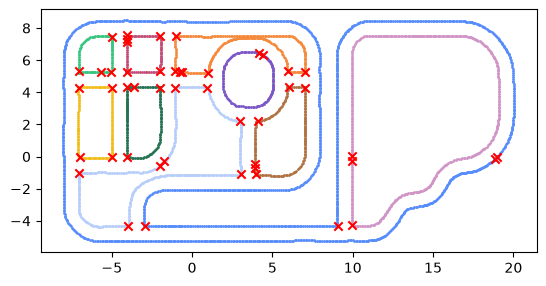

In [9]:
mc.plot_curves()

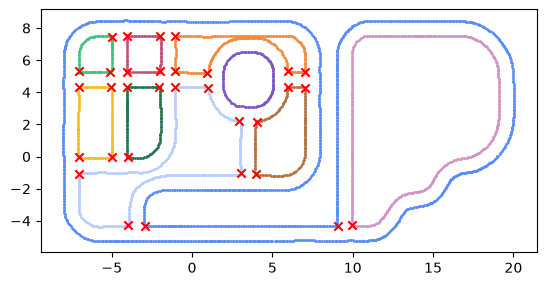

In [10]:
mc.preprocess()

mc.plot_curves()

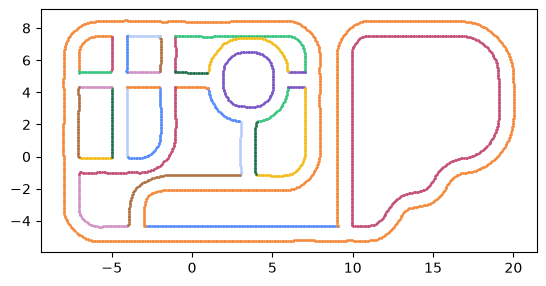

In [11]:
mc.split_curves_into_segments()

mc.estimate_track_width(0.9)
mc.identify_consecutive_track_segments()

mc.plot_segments()

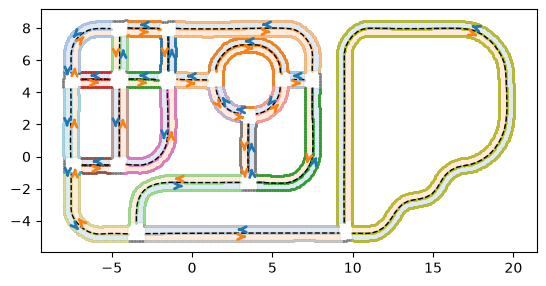

In [12]:
mc.clean_track_segment_maps()
mc.get_segment_track_separation()
mc.fit_lines_with_splines()

mc.plot_correspondences()